In [1]:
import zipfile

zip_path = "/content/Causal_Pricing_Week1_Dataset_Bundle.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/project_data")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [2]:
import os

for root, dirs, files in os.walk("/content/project_data"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/project_data/team_guide/DATA_DICTIONARY.csv
/content/project_data/shared_data/member_responsibilities.csv
/content/project_data/shared_data/competitor_pricing.csv
/content/project_data/shared_data/regional_transactions.csv
/content/project_data/shared_data/region_network.csv
/content/project_data/shared_data/market_context.csv
/content/project_data/shared_data/treatment_calendar.csv


In [3]:
import pandas as pd

# Load the three datasets
transactions = pd.read_csv(
    "/content/project_data/shared_data/regional_transactions.csv"
)

context = pd.read_csv(
    "/content/project_data/shared_data/market_context.csv"
)

competitors = pd.read_csv(
    "/content/project_data/shared_data/competitor_pricing.csv"
)

print("All three datasets loaded successfully!")

print("\nTransactions:", transactions.shape)
print("Market Context:", context.shape)
print("Competitor Pricing:", competitors.shape)

All three datasets loaded successfully!

Transactions: (25249, 21)
Market Context: (1944, 13)
Competitor Pricing: (23348, 13)


In [4]:
# Display the first 5 rows of the transactions dataset
transactions.head()

,transaction_id,transaction_date,order_hour,region_id,region_name,product_id,product_name,category,customer_segment,units,...,selling_price,discount_pct,promotion_flag,inventory_level,demand_index,dynamic_price_multiplier,revenue,pricing_treatment_flag,treatment_phase,channel
0,T00000001,2026-01-01,17,R01,North Metro,P001,Everyday Essentials,Essentials,Premium,1,...,35.30,5,1,83,1.2195,1.0,35.30,0,Pre-treatment,App
1,T00000002,2026-01-01,8,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,3,...,37.72,0,0,91,1.2195,1.0,113.17,0,Pre-treatment,App
2,T00000003,2026-01-01,15,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,2,...,36.48,0,0,111,1.2195,1.0,72.96,0,Pre-treatment,App
3,T00000004,2026-01-01,14,R01,North Metro,P001,Everyday Essentials,Essentials,New,2,...,37.50,0,0,109,1.2195,1.0,75.00,0,Pre-treatment,App
4,T00000005,2026-01-01,10,R01,North Metro,P002,Home Care Pack,Home,Returning,1,...,59.15,0,0,143,1.2195,1.0,59.15,0,Pre-treatment,App


In [5]:
# Check dataset information
print("TRANSACTIONS DATASET INFORMATION")
transactions.info()

print("\nMISSING VALUES")
print(transactions.isnull().sum())

print("\nDUPLICATE ROWS")
print(transactions.duplicated().sum())

TRANSACTIONS DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25249 entries, 0 to 25248
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   transaction_id            25249 non-null  object 
 1   transaction_date          25249 non-null  object 
 2   order_hour                25249 non-null  int64  
 3   region_id                 25249 non-null  object 
 4   region_name               25234 non-null  object 
 5   product_id                25249 non-null  object 
 6   product_name              25249 non-null  object 
 7   category                  25249 non-null  object 
 8   customer_segment          25249 non-null  object 
 9   units                     25249 non-null  int64  
 10  list_price                25249 non-null  float64
 11  selling_price             25224 non-null  float64
 12  discount_pct              25249 non-null  int64  
 13  promotion_flag            25

In [6]:
# Basic statistical analysis

print("TRANSACTION DATASET STATISTICS")

display(transactions.describe())

TRANSACTION DATASET STATISTICS


,order_hour,units,list_price,selling_price,discount_pct,promotion_flag,inventory_level,demand_index,dynamic_price_multiplier,revenue,pricing_treatment_flag
count,25249.00000,25249.000000,25249.000000,25224.000000,25249.000000,25249.000000,25249.000000,25249.000000,25249.000000,25249.000000,25249.000000
mean,15.01608,1.491623,84.444554,83.230887,1.497287,0.149550,120.556933,1.055302,1.000320,124.536605,0.070854
std,4.33039,0.783536,45.259058,44.806134,3.907599,0.356637,24.834565,0.134171,0.001489,101.388993,0.256586
min,8.00000,0.000000,32.460000,27.850000,0.000000,0.000000,22.000000,0.707300,0.998200,28.010000,0.000000
25%,11.00000,1.000000,52.770000,52.010000,0.000000,0.000000,104.000000,0.953900,1.000000,57.920000,0.000000
50%,15.00000,1.000000,75.460000,74.730000,0.000000,0.000000,120.000000,1.052500,1.000000,91.380000,0.000000
75%,19.00000,2.000000,114.600000,112.822500,0.000000,0.000000,137.000000,1.152100,1.000000,162.810000,0.000000
max,22.00000,4.000000,194.890000,196.150000,15.000000,1.000000,232.000000,1.428200,1.016000,780.900000,1.000000


In [7]:
print("MARKET CONTEXT DATASET")

display(context.head())

print("\nDATASET SHAPE")
print(context.shape)

print("\nDATASET INFORMATION")
context.info()

print("\nMISSING VALUES")
print(context.isnull().sum())

print("\nDUPLICATE ROWS")
print(context.duplicated().sum())

MARKET CONTEXT DATASET


,date,region_id,region_name,demand_index,seasonality_index,marketing_spend,holiday_flag,weekend_flag,local_event_flag,weather_index,inventory_pressure,region_income_index,network_exposure
0,2026-01-01,R01,North Metro,1.2195,1.0014,2635.93,0,0,0,1.0634,1.0246,1.08,0.0
1,2026-01-01,R02,South Metro,1.0557,1.0014,2402.43,0,0,0,1.0266,0.9805,1.04,0.0
2,2026-01-01,R03,East Metro,1.0052,1.0014,2349.27,0,0,0,0.9815,1.0412,0.98,0.0
3,2026-01-01,R04,West Metro,1.1043,1.0014,3002.88,0,0,0,1.0197,1.0037,1.06,0.0
4,2026-01-01,R05,Central,1.0684,1.0014,2097.59,0,0,0,0.9766,1.1264,1.00,0.0



DATASET SHAPE
(1944, 13)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1944 entries, 0 to 1943
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 1944 non-null   object 
 1   region_id            1944 non-null   object 
 2   region_name          1944 non-null   object 
 3   demand_index         1944 non-null   float64
 4   seasonality_index    1944 non-null   float64
 5   marketing_spend      1934 non-null   float64
 6   holiday_flag         1944 non-null   int64  
 7   weekend_flag         1944 non-null   int64  
 8   local_event_flag     1944 non-null   int64  
 9   weather_index        1944 non-null   float64
 10  inventory_pressure   1944 non-null   float64
 11  region_income_index  1944 non-null   float64
 12  network_exposure     1944 non-null   float64
dtypes: float64(7), int64(3), object(3)
memory usage: 197.6+ KB

MISSING VALUES
date            

In [8]:
print("COMPETITOR PRICING DATASET")

display(competitors.head())

print("\nDATASET SHAPE")
print(competitors.shape)

print("\nDATASET INFORMATION")
competitors.info()

print("\nMISSING VALUES")
print(competitors.isnull().sum())

print("\nDUPLICATE ROWS")
print(competitors.duplicated().sum())

COMPETITOR PRICING DATASET


,quote_id,quote_date,hour_bucket,region_id,region_name,product_id,product_name,competitor_id,competitor_price,competitor_discount_pct,competitor_stock_status,competitor_promo_flag,scrape_source
0,Q0000001,2026-01-01,09:00,R01,North Metro,P001,Everyday Essentials,C01,36.92,0,In Stock,0,Web Scrape
1,Q0000002,2026-01-01,21:00,R01,North Metro,P001,Everyday Essentials,C02,37.70,0,In Stock,0,Web Scrape
2,Q0000003,2026-01-01,18:00,R01,North Metro,P002,Home Care Pack,C01,59.73,0,Low Stock,0,Partner Feed
3,Q0000004,2026-01-01,13:00,R01,North Metro,P002,Home Care Pack,C02,58.73,0,In Stock,0,API
4,Q0000005,2026-01-01,21:00,R01,North Metro,P003,Beauty Combo,C01,80.54,0,In Stock,0,Partner Feed



DATASET SHAPE
(23348, 13)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23348 entries, 0 to 23347
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   quote_id                 23348 non-null  object 
 1   quote_date               23348 non-null  object 
 2   hour_bucket              23348 non-null  object 
 3   region_id                23348 non-null  object 
 4   region_name              23348 non-null  object 
 5   product_id               23348 non-null  object 
 6   product_name             23348 non-null  object 
 7   competitor_id            23348 non-null  object 
 8   competitor_price         23312 non-null  float64
 9   competitor_discount_pct  23348 non-null  int64  
 10  competitor_stock_status  23348 non-null  object 
 11  competitor_promo_flag    23348 non-null  int64  
 12  scrape_source            23348 non-null  object 
dtypes: float64(1), int64(2), obj

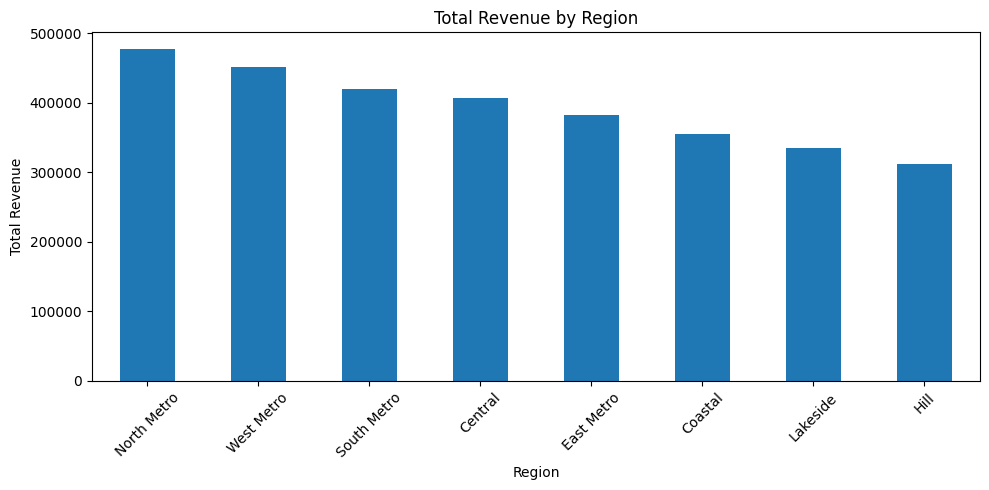

In [9]:
import matplotlib.pyplot as plt

region_revenue = transactions.groupby(
    "region_name"
)["revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

region_revenue.plot(kind="bar")

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

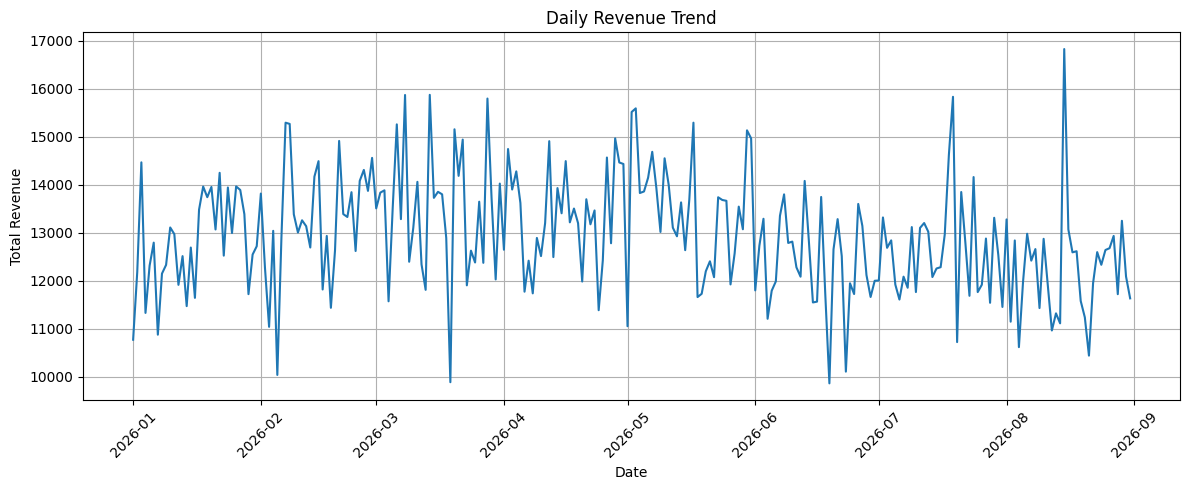

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert transaction date into datetime
transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

# Calculate daily revenue
daily_revenue = transactions.groupby(
    "transaction_date"
)["revenue"].sum()

# Create line graph
plt.figure(figsize=(12, 5))

plt.plot(daily_revenue.index, daily_revenue.values)

plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [11]:
import os

# Create reports folder
os.makedirs("/content/reports", exist_ok=True)

# Day 1 EDA Summary
eda_summary = """
# Day 1: Exploratory Data Analysis

## Project
Causal Inference & Synthetic Control Engine for Algorithmic Pricing

## Role
Member 4 - Data Analyst

## Datasets Explored

1. Regional Transactions: 25,249 rows, 21 columns
2. Competitor Pricing: 23,348 rows, 13 columns
3. Market Context: 1,944 rows, 13 columns

## Data Quality Findings

### Regional Transactions
- Missing region_name: 15
- Missing selling_price: 25
- Duplicate rows: 18

### Competitor Pricing
- Missing competitor_price: 36
- Duplicate rows: 20

### Market Context
- Missing marketing_spend: 10
- Duplicate rows: 0

## Analysis Performed

- Examined dataset structures
- Checked missing values
- Identified duplicate records
- Reviewed numerical statistics
- Visualized total revenue by region
- Visualized daily revenue trends

## Conclusion

Initial exploratory data analysis was completed.
Missing values and duplicates were identified
for further data cleaning.
"""

# Save report
with open("/content/reports/eda_summary.md", "w") as file:
    file.write(eda_summary)

print("Day 1 EDA Summary saved successfully!")

Day 1 EDA Summary saved successfully!


In [12]:
from google.colab import files

files.download("/content/reports/eda_summary.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>